# Module 4 - Design Principles: Line, Shape and Texture

**Name:** Clement Scaccia  
**Course:** Data Visualization  
**Tool:** Python (pandas, matplotlib)  
**Data:** Cboe VIX daily close, 1990 to 2026, the cleaned file from my Data Set Repair assignment (`Module4/cleaned_data/cboe_vix_daily_cleaned.csv`)

The VIX is the market's "fear gauge": it goes up when investors expect big swings in the S&P 500. I start with a default chart to show the problem, then make **two versions** of the same data, each with a different main point, using **line, shape/volume and texture** to make that point obvious.

| Version | Main point (focal point) |
|---|---|
| Baseline | none, everything looks equally important |
| Version 1 | **The single highest fear day ever:** March 16, 2020 (COVID), VIX closed at 82.69 |
| Version 2 | **2008 fear lasted way longer than COVID:** 170 trading days in a row above 30 vs 50 for COVID, even though COVID's peak was higher |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

vix = pd.read_csv("../Module4/cleaned_data/cboe_vix_daily_cleaned.csv", parse_dates=["DATE"])

# colors
GRAY = "#b5b4ae"; INK = "#0b0b0b"; INK2 = "#52514e"; BG = "#fcfcfb"
BLUE = "#2a78d6"; ORANGE = "#eb6834"

plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRAY, "xtick.color": INK2, "ytick.color": INK2})

avg = vix["CLOSE"].mean()
peak = vix.loc[vix["CLOSE"].idxmax()]
print(f"Rows: {len(vix)} | Average close: {avg:.2f} | Highest close: {peak.CLOSE} on {peak.DATE.date()}")

Rows: 9277 | Average close: 19.43 | Highest close: 82.69 on 2020-03-16


## Baseline: the default chart (the problem)

This is what you get with one line of code. It's not wrong, but it has no focal point: every day gets the same thin line in the same color, there's no reference for what "normal" is, and the reader has to figure out on their own what matters. That's the failure the two versions fix.

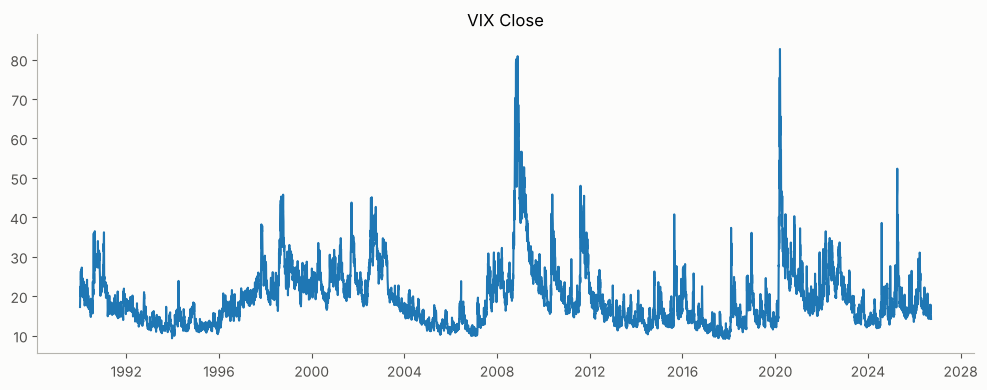

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(vix["DATE"], vix["CLOSE"])
ax.set_title("VIX Close")
plt.tight_layout()
plt.savefig("images/baseline.png", dpi=150)
plt.show()

## Version 1: focal point = the COVID peak (March 16, 2020)

**Main point:** the highest VIX close in the whole data set was March 16, 2020, at 82.69, more than 4 times the long-run average.

How I used the principles:
- **Line:** all 36 years are a thin light gray line so they step back as context. Only the COVID crash (Feb to May 2020) is drawn in a thick blue line, so the eye goes there first. A thin dashed line marks the long-run average (19.4) as a "normal" reference.
- **Shape / volume:** a filled area under the COVID section gives the spike weight, and a big circle sits on the exact peak day with a direct label.
- **Texture:** not needed here. With one focal point, adding texture would just be clutter, so I kept the rest of the chart plain on purpose.

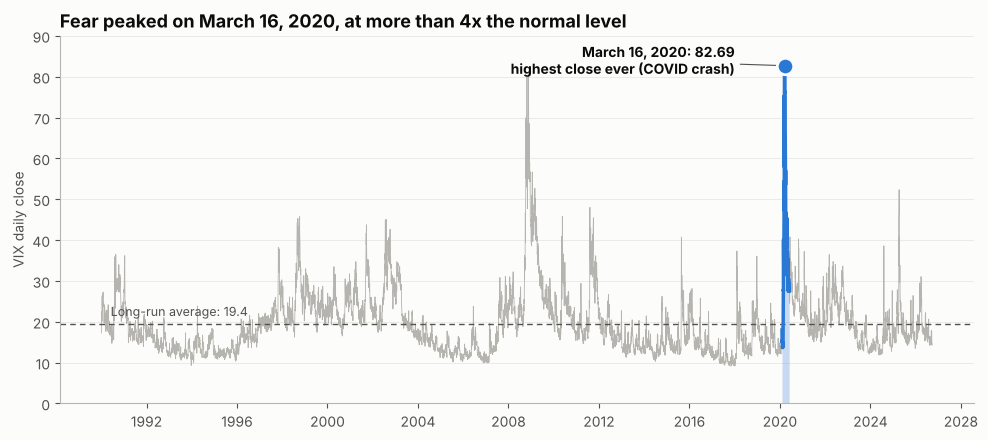

In [3]:
covid = vix[vix["DATE"].between("2020-02-01", "2020-05-31")]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(vix["DATE"], vix["CLOSE"], color=GRAY, linewidth=0.6)                       # context
ax.axhline(avg, color=INK2, linestyle=(0, (4, 3)), linewidth=1)                       # reference line
ax.text(pd.Timestamp("1990-06-01"), avg + 2, f"Long-run average: {avg:.1f}", color=INK2, fontsize=9)

ax.fill_between(covid["DATE"], 0, covid["CLOSE"], color=BLUE, alpha=0.25, linewidth=0)  # volume
ax.plot(covid["DATE"], covid["CLOSE"], color=BLUE, linewidth=2.5)                     # emphasized line
ax.scatter(peak.DATE, peak.CLOSE, s=140, color=BLUE, edgecolor=BG, linewidth=2, zorder=5)  # shape
ax.annotate(f"March 16, 2020: {peak.CLOSE:.2f}\nhighest close ever (COVID crash)",
            xy=(peak.DATE, peak.CLOSE), xytext=(pd.Timestamp("2018-01-01"), 84),
            fontsize=10, color=INK, fontweight="bold", ha="right", va="center",
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))

ax.set_ylim(0, 90)
ax.set_ylabel("VIX daily close", color=INK2)
ax.set_title("Fear peaked on March 16, 2020, at more than 4x the normal level", loc="left", fontsize=13, color=INK, fontweight="bold")
ax.grid(axis="y", color="#e8e7e2", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("images/version1_covid_peak.png", dpi=150)
plt.show()

## Version 2: focal point = how LONG the fear lasted (2008 vs 2020)

**Main point:** COVID had the highest peak, but the 2008 financial crisis kept the VIX above 30 for **170 trading days in a row** (Sep 15, 2008 to May 18, 2009), more than 3 times as long as COVID's **50 days** (Feb 27 to May 7, 2020). Height isn't the whole story, duration matters too.

First I calculate the streaks above 30 (a common "high fear" level):

In [4]:
THRESH = 30
vix["above"] = vix["CLOSE"] > THRESH
vix["streak_id"] = (vix["above"] != vix["above"].shift()).cumsum()
streaks = (vix[vix["above"]].groupby("streak_id")
           .agg(start=("DATE", "min"), end=("DATE", "max"), trading_days=("DATE", "size"), peak=("CLOSE", "max"))
           .sort_values("trading_days", ascending=False).reset_index(drop=True))
streaks.head(5)

,start,end,trading_days,peak
0,2008-09-15,2009-05-18,170,80.86
1,2011-08-04,2011-10-13,50,48.00
2,2020-02-27,2020-05-07,50,82.69
3,1998-08-21,1998-10-28,48,45.74
4,2002-08-27,2002-10-24,42,42.64


How I used the principles:
- **Line:** a thick dashed threshold line at 30 is the anchor of the chart, everything is about time spent above it. The VIX itself is a thin line that's dark only inside the two episodes.
- **Shape / volume:** only the part of the VIX **above 30** is filled, so the size of each filled shape is literally the amount of fear. The 2008 shape is long and wide, the COVID one is tall but narrow. Below the chart, two bars made from the same data show the length of each streak.
- **Texture:** 2008 is filled with diagonal hatching and COVID with a solid fill. That way the two periods are told apart by pattern and not only by color, which also works for colorblind readers and in black and white print.

I zoomed in to 2007 to 2021 so the two shapes are big enough to compare.

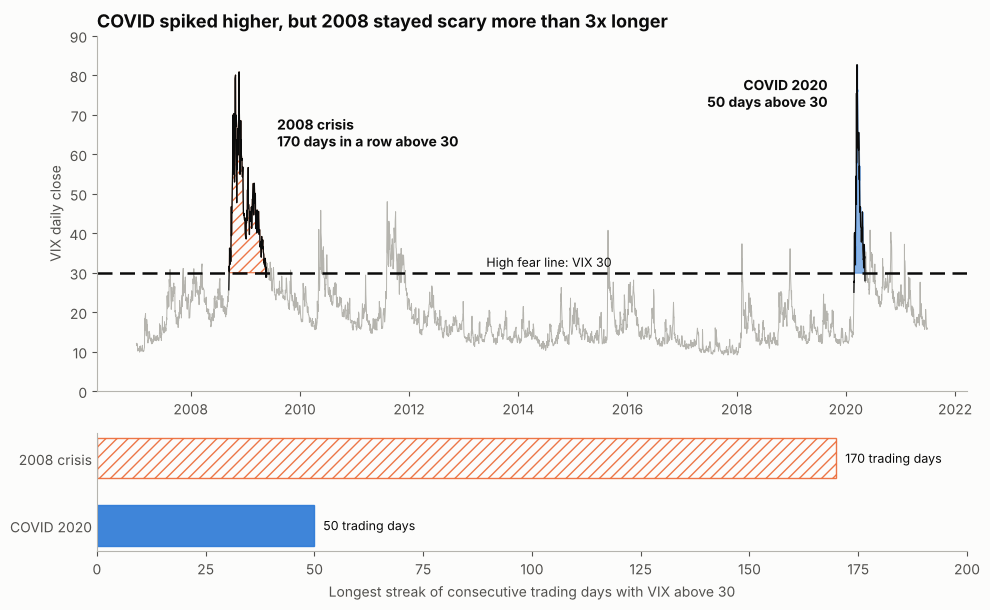

In [5]:
s08 = streaks.iloc[0]
s20 = streaks[streaks["start"].dt.year == 2020].iloc[0]
win = vix[vix["DATE"].between("2007-01-01", "2021-06-30")]

fig, (ax, axb) = plt.subplots(2, 1, figsize=(10, 6.2), gridspec_kw={"height_ratios": [3, 1]})

ax.plot(win["DATE"], win["CLOSE"], color=GRAY, linewidth=0.7)
for s, color, hatch, name in [(s08, ORANGE, "///", "2008 crisis"), (s20, BLUE, None, "COVID 2020")]:
    part = vix[vix["DATE"].between(s.start - pd.Timedelta(days=3), s.end + pd.Timedelta(days=3))]
    ax.plot(part["DATE"], part["CLOSE"], color=INK, linewidth=0.9)
    ax.fill_between(part["DATE"], THRESH, part["CLOSE"], where=part["CLOSE"] > THRESH,
                    facecolor=color if hatch is None else BG, edgecolor=color, hatch=hatch,
                    alpha=0.9 if hatch else 0.55, linewidth=0.8, interpolate=True)
ax.axhline(THRESH, color=INK, linestyle=(0, (6, 3)), linewidth=1.8)
ax.text(pd.Timestamp("2013-06-01"), THRESH + 1.5, "High fear line: VIX 30", fontsize=9, color=INK)
ax.text(pd.Timestamp("2009-08-01"), 62, f"2008 crisis\n{s08.trading_days} days in a row above 30", color=INK, fontsize=10, fontweight="bold")
ax.text(pd.Timestamp("2019-09-01"), 72, f"COVID 2020\n{s20.trading_days} days above 30", color=INK, fontsize=10, fontweight="bold", ha="right")
ax.set_ylim(0, 90)
ax.set_ylabel("VIX daily close", color=INK2)
ax.set_title("COVID spiked higher, but 2008 stayed scary more than 3x longer", loc="left", fontsize=13, color=INK, fontweight="bold")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

labels = ["2008 crisis", "COVID 2020"]
axb.barh(labels, [s08.trading_days, s20.trading_days], color=[BG, BLUE], edgecolor=[ORANGE, BLUE],
         hatch=["///", None], linewidth=1, height=0.6, alpha=0.9)
for i, d in enumerate([s08.trading_days, s20.trading_days]):
    axb.text(d + 2, i, f"{d} trading days", va="center", fontsize=9, color=INK)
axb.invert_yaxis()
axb.set_xlim(0, 200)
axb.set_xlabel("Longest streak of consecutive trading days with VIX above 30", color=INK2)
axb.tick_params(axis="y", length=0, labelsize=10)
plt.tight_layout()
plt.savefig("images/version2_fear_duration.png", dpi=150)
plt.show()

## Summary

| | Baseline | Version 1 | Version 2 |
|---|---|---|---|
| **Main point** | none | the single highest day (COVID, 82.69) | how long fear lasted (2008: 170 days vs COVID: 50) |
| **Line** | one default line | gray context, thick blue focus line, dashed average line | thick dashed threshold line at 30, thin VIX line |
| **Shape / volume** | none | filled area under the spike, circle on the peak | filled shapes above 30 (size = amount of fear), bars for streak length |
| **Texture** | none | left out on purpose | hatched 2008 vs solid COVID, so they're readable without color |

Same data, two different stories. Version 1 answers "when was it worst?" and Version 2 answers "which crisis was really worse?" The design choices decide which one the reader sees first.